# Lab Task 4 — PyTorch Regression Model

**Source:** *Understanding Deep Learning*, Laboratory Task 4.

**Instructor requirements:** Regression dataset; **MSE Loss**; **two fully connected layers**; **batch size 8**; **SGD optimizer**; **1000 epochs**.

This solution uses the built-in **diabetes regression dataset** from scikit-learn, split into training and testing sets. Input features and target values are standardized **using the training set only** so SGD can train stably. The predictions are converted back to their original units when reported.


In [1]:
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)
torch.set_num_threads(1)  # modest CPU use; training also works without this line

# Built-in regression dataset (442 samples, 10 features)
data = load_diabetes()
X = data.data.astype(np.float32)
y = data.target.astype(np.float32).reshape(-1, 1)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)

# Fit scaling on training data only
x_scaler = StandardScaler()
y_scaler = StandardScaler()
X_train_s = x_scaler.fit_transform(X_train).astype(np.float32)
X_test_s = x_scaler.transform(X_test).astype(np.float32)
y_train_s = y_scaler.fit_transform(y_train).astype(np.float32)

train_data = TensorDataset(torch.from_numpy(X_train_s), torch.from_numpy(y_train_s))
train_loader = DataLoader(train_data, batch_size=8, shuffle=True)

# Exactly TWO fully connected (nn.Linear) layers
model = nn.Sequential(
    nn.Linear(X_train.shape[1], 12),
    nn.ReLU(),
    nn.Linear(12, 1)
)
criterion = nn.MSELoss()             # required MSE loss
optimizer = torch.optim.SGD(model.parameters(), lr=0.004, weight_decay=0.05)  # required SGD
EPOCHS = 1000                      # required training epochs
BATCH_SIZE = 8                     # required batch size
assert train_loader.batch_size == BATCH_SIZE
assert len([module for module in model.modules() if isinstance(module, nn.Linear)]) == 2

print('Training samples:', len(train_data))
print('Test samples:', len(X_test))
print('Model:', model)


Training samples: 353
Test samples: 89
Model: Sequential(
  (0): Linear(in_features=10, out_features=12, bias=True)
  (1): ReLU()
  (2): Linear(in_features=12, out_features=1, bias=True)
)


In [2]:
# Train for 1000 epochs with batches of 8
history = []
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        predictions = model(xb)
        loss = criterion(predictions, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(xb)
    epoch_mse = total_loss / len(train_data)
    history.append(epoch_mse)
    if epoch == 0 or (epoch + 1) % 200 == 0:
        print(f'Epoch {epoch+1:4d}/{EPOCHS}: training MSE (scaled target) = {epoch_mse:.5f}')

# Evaluate on held-out testing data, restoring original units
model.eval()
with torch.no_grad():
    pred_test_scaled = model(torch.from_numpy(X_test_s)).numpy()
y_pred = y_scaler.inverse_transform(pred_test_scaled).reshape(-1)
y_true = y_test.reshape(-1)

mse_test = mean_squared_error(y_true, y_pred)
rmse_test = float(np.sqrt(mse_test))
mae_test = mean_absolute_error(y_true, y_pred)
r2_test = r2_score(y_true, y_pred)

print(f'\nTest MSE: {mse_test:.3f}')
print(f'Test RMSE: {rmse_test:.3f}')
print(f'Test MAE: {mae_test:.3f}')
print(f'Test R²: {r2_test:.3f}')

assert len(history) == 1000
assert np.isfinite(mse_test) and np.isfinite(rmse_test)


Epoch    1/1000: training MSE (scaled target) = 1.12355


Epoch  200/1000: training MSE (scaled target) = 0.44412


Epoch  400/1000: training MSE (scaled target) = 0.43883


Epoch  600/1000: training MSE (scaled target) = 0.43543


Epoch  800/1000: training MSE (scaled target) = 0.43332


Epoch 1000/1000: training MSE (scaled target) = 0.43230

Test MSE: 2609.875
Test RMSE: 51.087
Test MAE: 40.425
Test R²: 0.507


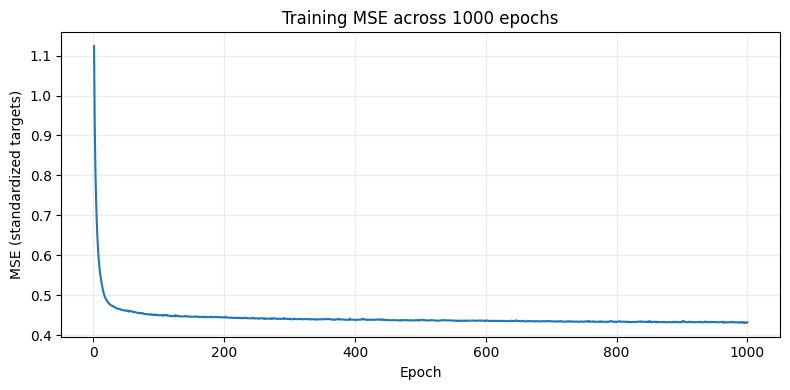

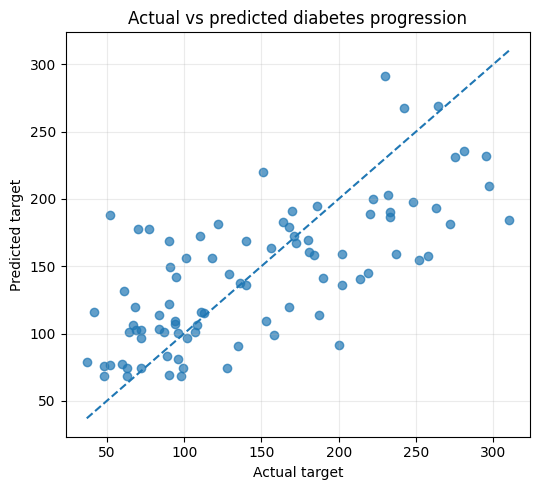

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(history)+1), history)
ax.set(title='Training MSE across 1000 epochs', xlabel='Epoch', ylabel='MSE (standardized targets)')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(y_true, y_pred, alpha=0.7)
lim_low = min(y_true.min(), y_pred.min())
lim_high = max(y_true.max(), y_pred.max())
ax.plot([lim_low, lim_high], [lim_low, lim_high], '--')
ax.set(title='Actual vs predicted diabetes progression', xlabel='Actual target', ylabel='Predicted target')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


**Interpretation:** The training curve shows how the model’s MSE changes over 1000 epochs. Test MSE and RMSE summarize prediction error on unseen samples, while R² describes how well the regression predicts variation in the diabetes progression target. The two linear layers are separated by ReLU; the last layer has no activation because regression predictions are continuous. The evaluation metrics come from the code output and should not be claimed before running it.
